# TexTag: Test Set Evaluation

The final model (fine-tuned ResNet18, `models/textag.pt`) on the **1,880 test images** it has never seen.
Until now we only looked at the validation set, so this is the honest score.

Sections:
1. Setup
2. Predict
3. Overall scores
4. Test vs validation
5. Per-class scores
6. Confusion matrix
7. Mistakes
8. Findings

| Metric | Question it answers |
|---|---|
| Accuracy | What share of all images did it get right? |
| Top-3 accuracy | Is the right answer among its 3 best guesses? (the web app shows the top 3) |
| Precision (per class) | When it says "cracked", how often is it really cracked? |
| Recall (per class) | Of all the real "cracked" images, how many did it find? |
| F1 | One number combining precision and recall |
| Macro average | Average over all 47 classes, each counted equally (fair here: classes are balanced) |

## 1. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_recall_fscore_support

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from textag.data import dataset
from textag.model import resnet18

plt.rcParams["figure.dpi"] = 72
%config InlineBackend.figure_formats = ["jpeg"]
device = "cuda" if torch.cuda.is_available() else "cpu"

checkpoint = torch.load(ROOT / "models" / "textag.pt", map_location=device)
classes = checkpoint["classes"]
model = resnet18(num_classes=len(classes), pretrained=False, freeze_backbone=False)
model.load_state_dict(checkpoint["state_dict"])
model.to(device).eval()
print(f"loaded {checkpoint['arch']}, {len(classes)} classes, device: {device}")

loaded resnet18, 47 classes, device: cpu


## 2. Predict

Test images get the same deterministic preprocessing as validation (resize 256, center crop 224, normalize).
No shuffling, so predictions line up with the file list.

In [2]:
test_ds = dataset("test")
test_dl = torch.utils.data.DataLoader(test_ds, batch_size=64, shuffle=False, num_workers=2)

all_probs, all_true = [], []
with torch.inference_mode():
    for X, y in test_dl:
        probs = torch.softmax(model(X.to(device)), dim=1)
        all_probs.append(probs.cpu())
        all_true.append(y)

probs = torch.cat(all_probs).numpy()
y_true = torch.cat(all_true).numpy()
y_pred = probs.argmax(axis=1)
top3 = np.argsort(-probs, axis=1)[:, :3]
print("predictions:", len(y_pred))

predictions: 1880


## 3. Overall scores

In [3]:
acc = accuracy_score(y_true, y_pred)
top3_acc = np.mean([t in row for t, row in zip(y_true, top3)])
prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)

overall = pd.Series({
    "accuracy": acc,
    "top-3 accuracy": top3_acc,
    "macro precision": prec,
    "macro recall": rec,
    "macro F1": f1,
    "random guessing": 1 / len(classes),
})
overall.map("{:.1%}".format).to_frame("test set")

,test set
accuracy,62.3%
top-3 accuracy,82.6%
macro precision,63.4%
macro recall,62.3%
macro F1,62.0%
random guessing,2.1%


## 4. Test vs validation

If test accuracy is close to validation accuracy, the model wasn't accidentally tuned to the validation set
(we used validation to pick the best epoch).

In [4]:
VAL_ACC = 0.624   # from 03_resnet.ipynb
pd.Series({"validation accuracy": VAL_ACC, "test accuracy": acc, "difference": acc - VAL_ACC}).map("{:+.1%}".format).str.lstrip("+").to_frame("")

,
validation accuracy,62.4%
test accuracy,62.3%
difference,-0.1%


## 5. Per-class scores

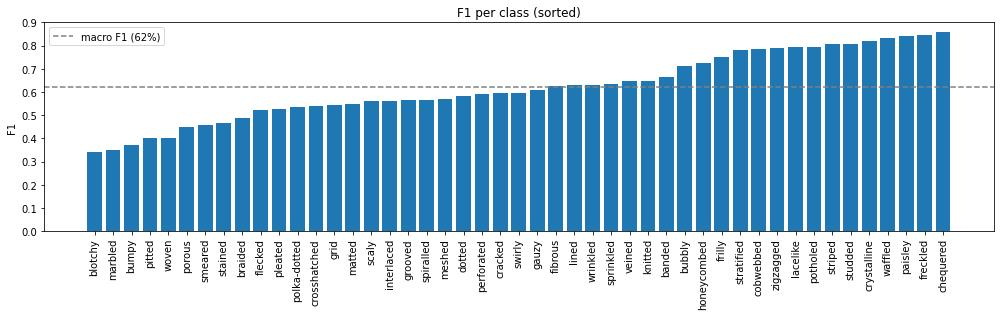

In [5]:
report = pd.DataFrame(classification_report(y_true, y_pred, target_names=classes, output_dict=True, zero_division=0)).T
per_class = report.loc[classes, ["precision", "recall", "f1-score"]].sort_values("f1-score")

plt.figure(figsize=(14, 4.5))
plt.bar(per_class.index, per_class["f1-score"])
plt.axhline(f1, color="gray", linestyle="--", label=f"macro F1 ({f1:.0%})")
plt.xticks(rotation=90)
plt.ylabel("F1")
plt.title("F1 per class (sorted)")
plt.legend()
plt.tight_layout()
plt.show()

In [6]:
fmt = {"precision": "{:.0%}", "recall": "{:.0%}", "f1-score": "{:.0%}"}
print("Worst 5 classes")
display(per_class.head(5).style.format(fmt))
print("Best 5 classes")
display(per_class.tail(5)[::-1].style.format(fmt))

Worst 5 classes


,precision,recall,f1-score
blotchy,33%,35%,34%
marbled,59%,25%,35%
bumpy,40%,35%,37%
pitted,60%,30%,40%
woven,52%,32%,40%


Best 5 classes


,precision,recall,f1-score
chequered,82%,90%,86%
freckled,87%,82%,85%
paisley,83%,85%,84%
waffled,86%,80%,83%
crystalline,79%,85%,82%


## 6. Confusion matrix

Rows = true class, columns = predicted class. A perfect model has everything on the diagonal.
Each row is shown as a share of that class's 40 test images.

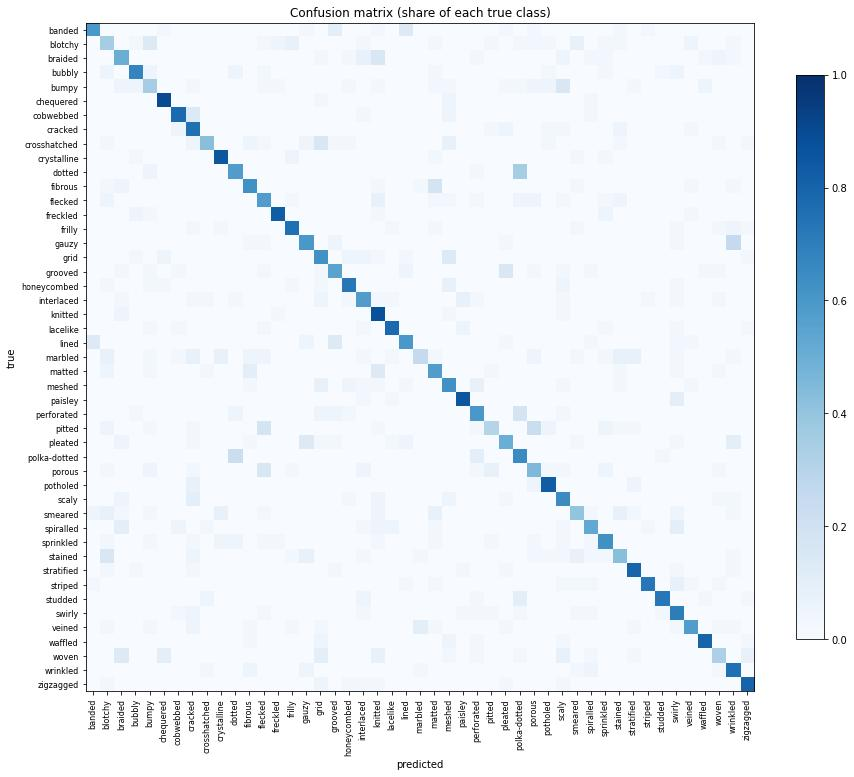

In [7]:
cm = confusion_matrix(y_true, y_pred, labels=range(len(classes)))
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(13, 12))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(classes)))
ax.set_yticks(range(len(classes)))
ax.set_xticklabels(classes, rotation=90, fontsize=8)
ax.set_yticklabels(classes, fontsize=8)
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title("Confusion matrix (share of each true class)")
fig.colorbar(im, ax=ax, shrink=0.7)
plt.tight_layout()
plt.show()

The 47×47 grid is hard to read, so here are the **10 most common mistakes** as a table
(true → predicted, out of 40 test images per class).

In [8]:
mistakes = [
    {"true": classes[i], "predicted": classes[j], "count": cm[i, j]}
    for i in range(len(classes)) for j in range(len(classes)) if i != j and cm[i, j] > 0
]
top_mistakes = pd.DataFrame(mistakes).sort_values("count", ascending=False).head(10).reset_index(drop=True)
top_mistakes

,true,predicted,count
0,dotted,polka-dotted,14
1,gauzy,wrinkled,10
2,pitted,porous,9
3,polka-dotted,dotted,9
4,perforated,polka-dotted,7
5,pitted,flecked,7
6,fibrous,matted,7
7,stained,blotchy,6
8,bumpy,scaly,6
9,braided,knitted,6


Were the look-alike pairs we guessed in the EDA actually confused? (count in both directions, out of 80 images)

In [9]:
eda_pairs = [("dotted", "polka-dotted"), ("banded", "striped"), ("grid", "chequered"), ("pitted", "porous")]
idx = {c: i for i, c in enumerate(classes)}
pd.DataFrame([
    {"pair": f"{a} / {b}",
     "first → second": cm[idx[a], idx[b]],
     "second → first": cm[idx[b], idx[a]],
     "total (of 80)": cm[idx[a], idx[b]] + cm[idx[b], idx[a]]}
    for a, b in eda_pairs
])

,pair,first → second,second → first,total (of 80)
0,dotted / polka-dotted,14,9,23
1,banded / striped,1,1,2
2,grid / chequered,2,1,3
3,pitted / porous,9,3,12


## 7. Mistakes

12 random wrong predictions. Are they understandable mistakes, or nonsense?

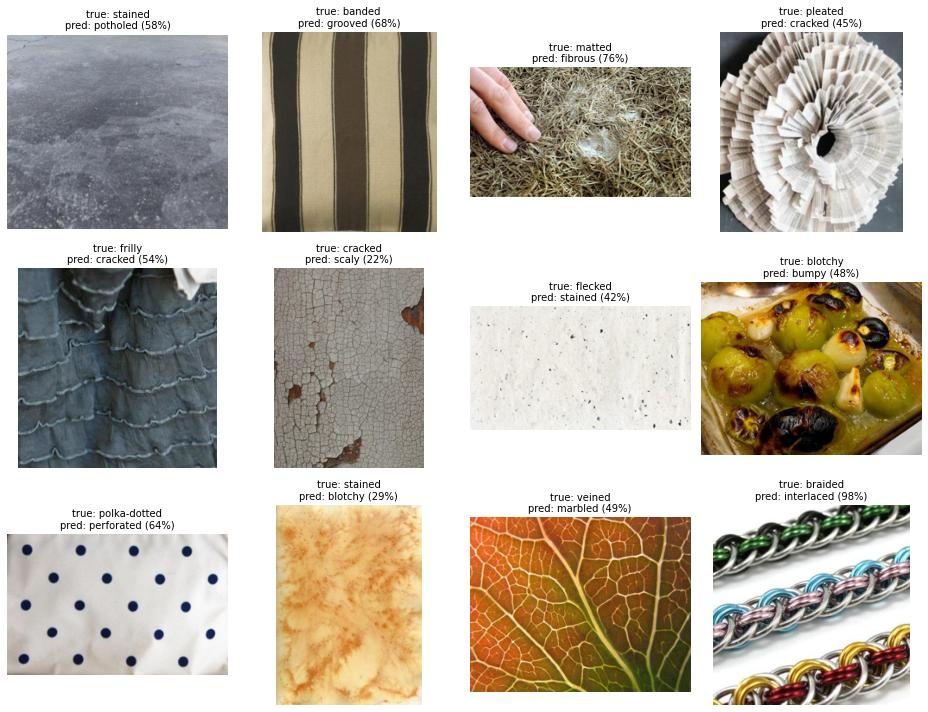

In [10]:
wrong = np.where(y_pred != y_true)[0]
rng = np.random.default_rng(0)
show = rng.choice(wrong, size=min(12, len(wrong)), replace=False)

fig, axes = plt.subplots(3, 4, figsize=(13, 10))
for ax, i in zip(axes.flat, show):
    im = Image.open(test_ds._image_files[i]).convert("RGB")
    im.thumbnail((256, 256))
    ax.imshow(im)
    ax.set_title(f"true: {classes[y_true[i]]}\npred: {classes[y_pred[i]]} ({probs[i, y_pred[i]]:.0%})", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 8. Findings

- **Test accuracy 62.3%**, almost identical to validation (62.4%). Picking the best epoch on validation didn't inflate the score, so this is an honest estimate of real-world accuracy.
- **Top-3 accuracy 82.6%:** the correct tag is among the app's 3 suggestions about 4 times out of 5. That fits a tagging tool, where the model suggests and a person confirms.
- **Balanced:** macro precision 63%, recall 62%, F1 62%. No large bias toward particular classes overall.
- **Best classes** are regular, distinctive patterns: chequered (F1 86%), freckled, paisley, waffled, crystalline. **Worst** are vague, irregular ones: blotchy (34%), marbled, bumpy, pitted, woven. Marbled has 59% precision but only 25% recall: the model rarely says "marbled", but is usually right when it does.
- **EDA guesses were half right:** dotted / polka-dotted is the biggest confusion (23 of 80 images; dotted → polka-dotted alone is 14 of 40), and pitted / porous is high too (12). Banded / striped (2) and grid / chequered (3) turned out not to be a problem.
- **Mistakes are mostly understandable:** e.g. polka-dotted → perforated, chainmail labelled braided → interlaced, a leaf labelled veined → marbled. Some images arguably fit both labels, and DTD gives each image only one.